# The Brazilian factors, original and orthogonal

The seven local factors of the companion repository, [brazil-equity-factors](https://github.com/pedroandion/brazil-equity-factors), before and after the SW/L transformation of [`01_paper_replication`](01_paper_replication.ipynb).

| Factor | Long minus short |
|---|---|
| `Mkt_RF` | Ibovespa minus the SELIC rate |
| `SMB` | small minus big market value |
| `HML` | high minus low book-to-price |
| `RMW` | high minus low gross profit over total assets |
| `CMA` | low minus high growth of total assets |
| `WML` | winners minus losers over the last 12 months, skipping the last one |
| `BAB` | low beta minus high beta, each side scaled to a beta of one |

Except for the market, each factor is built from the top 30% and the bottom 30% of the investable universe on its signal, with equal weights, rebalanced on the first business day of each month (notebook `03_historical_betas` of the companion). For BAB, the signal is the shrunk beta of Frazzini and Pedersen (2014), and each leg is scaled by the inverse of its average beta when it is formed, as they do, so that the factor is neutral to the market. The companion's BAB holds the same legs without that scaling, so it is dollar-neutral but not beta-neutral; the next section compares the two.

When these factors were used in a portfolio construction project, BAB had to be dropped: its correlation with the market made the factor model unstable. As the next section shows, most of that correlation came from the way BAB was built. The transformation keeps all seven factors and splits the systematic risk among them without ambiguity. This notebook looks at how much the factors overlap and at what the orthogonal factors are.

In [1]:
# Library imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from pathlib import Path
from statsmodels.stats.outliers_influence import variance_inflation_factor

from orthofactors.data import load_brazil_factors, to_monthly, BRAZIL_FACTORS, MONTHLY_SAMPLE
from orthofactors.orthogonalization import (orthogonalize_swl, orthogonalize_swl_correlation, orthogonalize_pca,
                                            orthogonalize_gs, calculate_frobenius_norm)
from orthofactors.plotting import set_style, factor_colors, DIVERGING
import statsmodels.api as sm

set_style()
Path('results').mkdir(exist_ok = True)
colors = factor_colors(BRAZIL_FACTORS)

## Data

Daily returns from 2010-01-05, when BAB starts, to 2026-07-23. The monthly returns compound the daily ones, as the companion does, and keep the full months, February 2010 to June 2026.

In [2]:
daily = load_brazil_factors()[BRAZIL_FACTORS]
monthly = to_monthly(daily).loc[MONTHLY_SAMPLE]
print(f'Daily: {len(daily)} days, {daily.index[0]:%Y-%m-%d} to {daily.index[-1]:%Y-%m-%d}')
print(f'Monthly: {len(monthly)} months, {monthly.index[0]:%Y-%m} to {monthly.index[-1]:%Y-%m}')

Daily: 4157 days, 2010-01-05 to 2026-07-23
Monthly: 197 months, 2010-02 to 2026-06


## Two versions of BAB

The companion's BAB is long the 30% lowest-beta stocks and short the 30% highest-beta ones, one real each. Since the long side has a beta below one and the short side a beta above one, that factor is short the market. Frazzini and Pedersen scale each side to a beta of one: $BAB = (r_L - r_f)/eta_L - (r_H - r_f)/eta_H$, where $eta_L$ and $eta_H$ are the average betas of the two legs when they are formed. The betas are the shrunk Frazzini-Pedersen betas against the IBrX of the companion's signal.

In [3]:
dollar_neutral = to_monthly(load_brazil_factors(bab = 'dollar_neutral')[BRAZIL_FACTORS]).loc[MONTHLY_SAMPLE]
legs = pd.read_csv('data/brazil_bab_legs.csv.gz', index_col = 'Date', parse_dates = True).loc[daily.index]
risk_free = load_brazil_factors()['Risk_Free']
leg_excess = to_monthly(legs[['Low_Beta', 'High_Beta']].sub(risk_free, axis = 0)).loc[MONTHLY_SAMPLE]

series = {'Low-beta leg': leg_excess['Low_Beta'], 'High-beta leg': leg_excess['High_Beta'],
          'BAB, dollar-neutral (companion)': dollar_neutral['BAB'], 'BAB, beta-neutral': monthly['BAB']}
ex_ante = {'Low-beta leg': legs['Low_Beta_Beta'].mean(), 'High-beta leg': legs['High_Beta_Beta'].mean(),
           'BAB, dollar-neutral (companion)': (legs['Low_Beta_Beta'] - legs['High_Beta_Beta']).mean(), 'BAB, beta-neutral': 0.0}
rows = {}
for name, returns in series.items():
    capm = sm.OLS(returns, sm.add_constant(monthly['Mkt_RF'])).fit()
    rows[name] = {'Average ex-ante beta': ex_ante[name], 'Beta on Mkt_RF': capm.params['Mkt_RF'], 'R² on Mkt_RF': capm.rsquared,
                  'Mean': returns.mean() * 12, 'Volatility': returns.std() * np.sqrt(12),
                  't-statistic': returns.mean() / returns.std() * np.sqrt(len(returns))}
pd.DataFrame(rows).T.style.format({'Average ex-ante beta': '{:.2f}', 'Beta on Mkt_RF': '{:.2f}', 'R² on Mkt_RF': '{:.1%}',
                                    'Mean': '{:.2%}', 'Volatility': '{:.2%}', 't-statistic': '{:.2f}'})

,Average ex-ante beta,Beta on Mkt_RF,R² on Mkt_RF,Mean,Volatility,t-statistic
Low-beta leg,0.73,0.60,64.8%,1.57%,15.34%,0.41
High-beta leg,1.28,1.45,82.4%,-2.28%,32.97%,-0.28
"BAB, dollar-neutral (companion)",-0.54,-0.86,57.0%,3.37%,23.54%,0.58
"BAB, beta-neutral",0.00,-0.37,20.9%,4.98%,16.62%,1.22


Both legs move with the market, but the high-beta leg much more: their betas on Mkt_RF are 0.60 and 1.45. Long one real of the first and short one real of the second gives a beta of −0.86, and the market explains 57% of the variance of the companion's BAB. Scaling each leg by its ex-ante beta cuts the beta to −0.37 and the R² to 21%. It does not reach zero because the shrunk betas understate the spread between the legs, 0.73 and 1.28 ex ante against 0.60 and 1.45 ex post.

The beta-neutral BAB also has a higher mean, 5.0% a year against 3.4%, with a lower volatility, 16.6% against 23.5%: the high-beta stocks lost to the SELIC rate, by 2.3% a year, while the low-beta ones beat it. The rest of this repository uses the beta-neutral BAB, and [`03_strategy_decomposition`](03_strategy_decomposition.ipynb) repeats the main results with the dollar-neutral one.

In [4]:
# Annualized mean and volatility, Sharpe ratio and t-statistic of the mean, from monthly returns
def moments(returns):
    return pd.DataFrame({'Mean': returns.mean() * 12, 'Volatility': returns.std() * np.sqrt(12),
                         'Sharpe ratio': returns.mean() / returns.std() * np.sqrt(12),
                         't-statistic': returns.mean() / returns.std() * np.sqrt(len(returns))})

moments(monthly).style.format({'Mean': '{:.2%}', 'Volatility': '{:.2%}', 'Sharpe ratio': '{:.2f}', 't-statistic': '{:.2f}'})

,Mean,Volatility,Sharpe ratio,t-statistic
Mkt_RF,-1.33%,20.67%,-0.06,-0.26
SMB,-4.28%,15.30%,-0.28,-1.13
HML,-1.30%,16.92%,-0.08,-0.31
RMW,4.06%,13.21%,0.31,1.25
CMA,0.16%,11.67%,0.01,0.06
WML,16.92%,18.58%,0.91,3.69
BAB,4.98%,16.62%,0.30,1.22


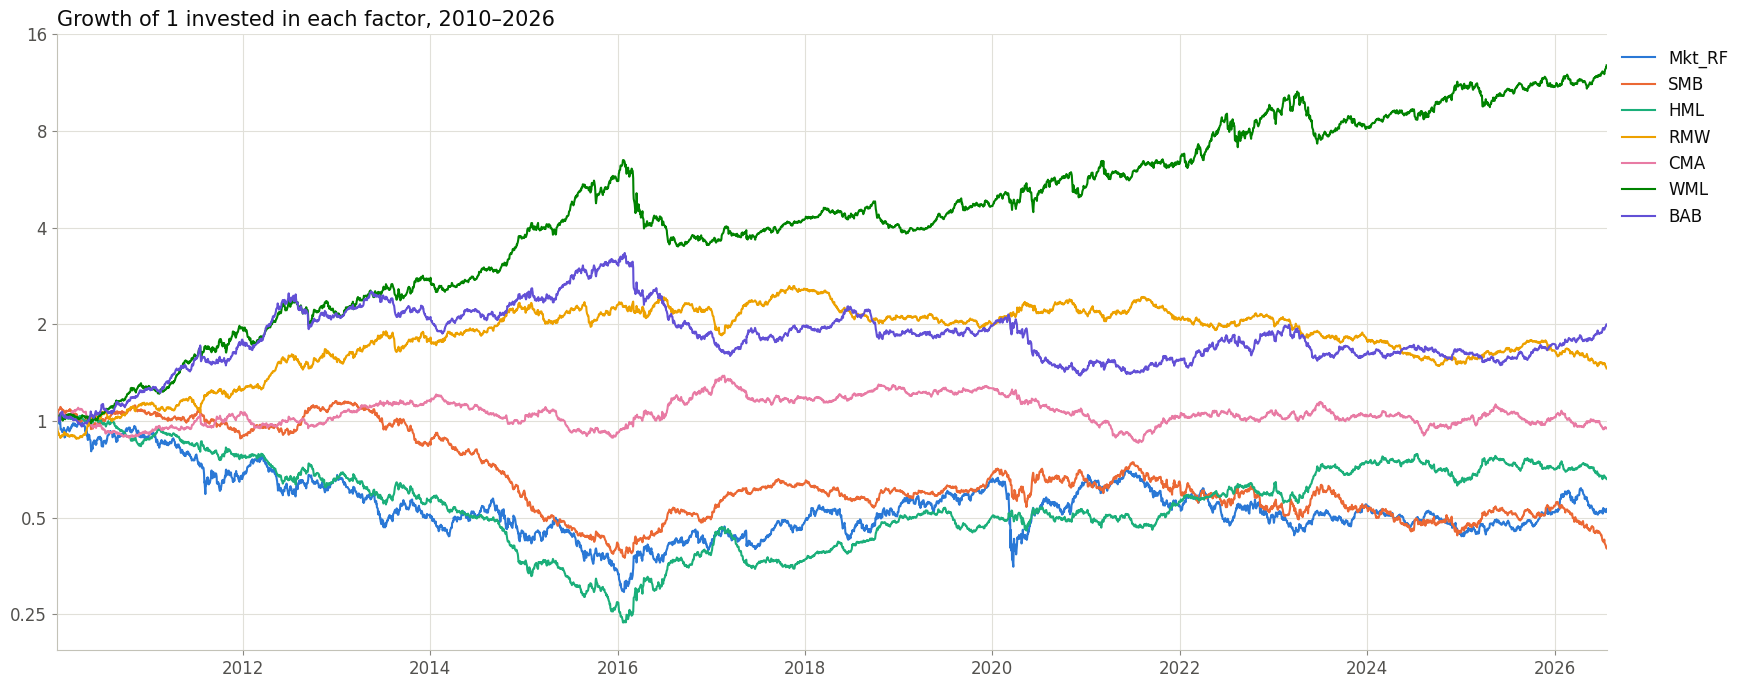

In [5]:
# Cumulative return of each factor, log scale
fig, ax = plt.subplots()
for factor in BRAZIL_FACTORS:
    ax.plot(daily.index, daily[factor].add(1).cumprod(), color = colors[factor], label = factor)
ax.set_yscale('log')
ax.set_yticks([0.25, 0.5, 1, 2, 4, 8, 16])
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f'{y:g}'))
ax.yaxis.set_minor_locator(ticker.NullLocator())
ax.margins(x = 0)
ax.set_title('Growth of 1 invested in each factor, 2010–2026')
ax.legend(loc = 'upper left', bbox_to_anchor = (1.0, 1.0))
plt.show()

Over these 16 years the market lost to the SELIC rate, by 1.3% a year, and only momentum has a clearly positive premium: 16.9% a year, with a t-statistic of 3.7. BAB (5.0%) and profitability (4.1%) are positive but not significant, and size and value are negative. These are in-sample means of single-sort portfolios without costs, so they say little about premia in general. What matters here is how the factors move together.

## How much the factors overlap

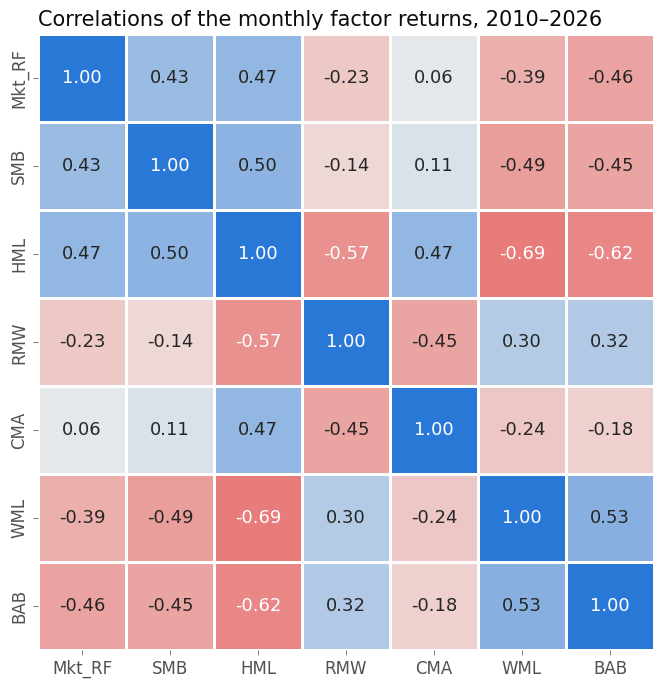

In [6]:
fig, ax = plt.subplots(figsize = (10, 8))
sns.heatmap(monthly.corr().round(2) + 0.0, annot = True, fmt = '.2f', cmap = DIVERGING, vmin = -1, vmax = 1, square = True,
            cbar = False, linewidths = 2, linecolor = 'white', annot_kws = {'size': 13}, ax = ax)
ax.set_title('Correlations of the monthly factor returns, 2010–2026')
ax.grid(False)
plt.show()

In [7]:
# Variance inflation factors of the monthly factors, with each version of BAB and without it
def vif(factors):
    X = factors.assign(const = 1.0).values
    return pd.Series([variance_inflation_factor(X, i) for i in range(factors.shape[1])], index = factors.columns)

pd.DataFrame({'Beta-neutral BAB': vif(monthly), 'Dollar-neutral BAB (companion)': vif(dollar_neutral),
              'Without BAB': vif(monthly.drop(columns = 'BAB'))}).reindex(BRAZIL_FACTORS).round(2)

,Beta-neutral BAB,Dollar-neutral BAB (companion),Without BAB
Mkt_RF,1.47,2.43,1.42
SMB,1.58,1.81,1.56
HML,3.66,3.67,3.38
RMW,1.65,1.66,1.65
CMA,1.45,1.44,1.44
WML,2.07,2.06,2.03
BAB,1.80,4.06,NaN


In [8]:
# Eigenvalues of the correlation matrix: the share of the total variance of the standardized factors along each axis
eigenvalues = np.linalg.eigvalsh(monthly.corr())[::-1]
pd.DataFrame({'Eigenvalue': eigenvalues, 'Share': eigenvalues / eigenvalues.sum()},
             index = [f'PC{i + 1}' for i in range(len(eigenvalues))]).T.round(3)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
Eigenvalue,3.413,1.252,0.665,0.552,0.466,0.449,0.204
Share,0.488,0.179,0.095,0.079,0.067,0.064,0.029


The factors overlap more than the US factors of the paper, whose largest correlation was 0.65. Value is the hub, with −0.69 against momentum, −0.62 against BAB and −0.57 against profitability. Momentum and BAB move together (+0.53): in Brazil the low-beta stocks have tended to be the winners and the more expensive stocks.

With the dollar-neutral BAB of the companion, BAB was the most connected factor, at −0.75 against the market, and had the largest variance inflation factor, 4.1: that is the instability that led to dropping it before. With the beta-neutral version its inflation factor falls to 1.8, and the market's from 2.4 to 1.5, so most of the multicollinearity came from the construction of BAB, not from the low-beta effect. The largest inflation factor is now HML's, 3.7, and the first principal component holds 49% of the variance of the standardized factors.

## The orthogonal factors

In [9]:
monthly_ortho, S, Psi = orthogonalize_swl(monthly, return_matrices = True)
daily_ortho, _, Psi_daily = orthogonalize_swl(daily, return_matrices = True)

pd.Series({'Largest correlation between two orthogonal factors': (monthly_ortho.corr() - np.eye(7)).abs().max().max(),
           'Largest relative change of a volatility': (monthly_ortho.std() / monthly.std() - 1).abs().max()})

Largest correlation between two orthogonal factors    8.732440e-16
Largest relative change of a volatility               6.661338e-16
dtype: float64

In [10]:
# Resemblance: correlation of each factor with its orthogonal version
resemblance = pd.DataFrame({'Monthly': np.diag(Psi), 'Daily': np.diag(Psi_daily)}, index = BRAZIL_FACTORS)
resemblance.T.round(3)

,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB
Monthly,0.946,0.914,0.813,0.920,0.937,0.897,0.896
Daily,0.982,0.949,0.846,0.932,0.961,0.921,0.918


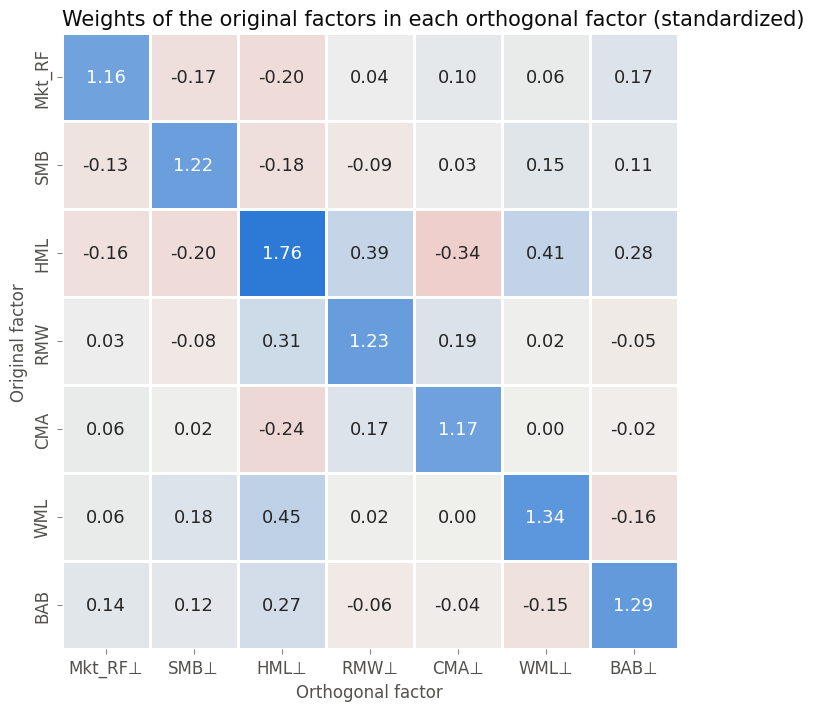

In [11]:
# What each orthogonal factor is made of: column k holds the weights of the standardized original factors
# in the standardized orthogonal factor k, that is diag(σ) S diag(1/σ)
composition = S.mul(monthly.std(), axis = 0).div(monthly.std(), axis = 1)

fig, ax = plt.subplots(figsize = (11, 8))
sns.heatmap(composition.round(2) + 0.0, annot = True, fmt = '.2f', cmap = DIVERGING, center = 0, vmin = -1.8, vmax = 1.8,
            square = True, cbar = False, linewidths = 2, linecolor = 'white', annot_kws = {'size': 13}, ax = ax)
ax.set_xticklabels([f'{f}⊥' for f in BRAZIL_FACTORS])
ax.set_xlabel('Orthogonal factor')
ax.set_ylabel('Original factor')
ax.set_title('Weights of the original factors in each orthogonal factor (standardized)')
ax.grid(False)
plt.show()

The resemblance is high, from 0.81 (HML) to 0.95 (the market) in monthly data and from 0.85 to 0.98 in daily data, where the factors are less correlated. It is lower than in the paper because the Brazilian factors overlap more. The heatmap shows how the overlap is removed: each orthogonal factor adds the factors it was negatively correlated with and subtracts the ones it was positively correlated with.

- **HML⊥** changes the most. It adds momentum (0.45), profitability (0.31) and BAB (0.27), and subtracts investment, the market and size: it is value without its bets against winners, profitable firms and low-beta stocks.
- **Mkt_RF⊥** stays close to the market (1.16), with small adjustments for value, size and BAB.
- **BAB⊥** adds value (0.28), the market (0.17) and size (0.11), and subtracts momentum (0.16).

## The premia change

In [12]:
# Annualized means of the original and the orthogonal factors, with their t-statistics, and the t-statistic of the
# mean difference, a paired test like the one in the paper
difference = monthly_ortho - monthly
premia = pd.DataFrame({'Original': monthly.mean() * 12, 't original': moments(monthly)['t-statistic'],
                       'Orthogonal': monthly_ortho.mean() * 12, 't orthogonal': moments(monthly_ortho)['t-statistic'],
                       't of the difference': difference.mean() / difference.std() * np.sqrt(len(difference))})
premia.style.format({'Original': '{:.2%}', 'Orthogonal': '{:.2%}', 't original': '{:.2f}', 't orthogonal': '{:.2f}',
                     't of the difference': '{:.2f}'})

,Original,t original,Orthogonal,t orthogonal,t of the difference
Mkt_RF,-1.33%,-0.26,1.55%,0.30,1.71
SMB,-4.28%,-1.13,-2.12%,-0.56,1.37
HML,-1.30%,-0.31,8.57%,2.05,3.87
RMW,4.06%,1.25,4.94%,1.52,0.68
CMA,0.16%,0.06,0.91%,0.32,0.74
WML,16.92%,3.69,20.60%,4.49,1.77
BAB,4.98%,1.22,2.67%,0.65,-1.23


The premia change, as in the paper. HML⊥ earns 8.6% a year against −1.3% for HML, and the difference is significant (t-statistic of 3.9). WML⊥ earns 20.6% against 16.9%, and BAB⊥ 2.7% against 5.0%. The heatmap explains these moves: HML⊥ holds a share of momentum, the factor with the largest premium.

So the orthogonal premia mix the premia of the factors that make up each orthogonal factor. They are a by-product, not the point: the transformation is for splitting risk, and the next notebooks use it that way.

## SW/L against PCA and Gram-Schmidt

The same comparison as Table 1 of the paper, with all seven factors at once. Gram-Schmidt depends on the order: a factor placed first stays unchanged, and the later it comes, the more it changes, so the table shows each factor in the last position.

In [13]:
pca = orthogonalize_pca(monthly)
gs_last = {f: orthogonalize_gs(monthly, [g for g in BRAZIL_FACTORS if g != f] + [f])[f] for f in BRAZIL_FACTORS}
correlation_version = orthogonalize_swl_correlation(monthly)

comparison = pd.DataFrame({'SW/L': resemblance['Monthly'],
                           'SW/L, correlation version': [monthly[f].corr(correlation_version[f]) for f in BRAZIL_FACTORS],
                           'PCA': [monthly[f].corr(pca[f]) for f in BRAZIL_FACTORS],
                           'Gram-Schmidt, factor last': [monthly[f].corr(gs_last[f]) for f in BRAZIL_FACTORS]},
                          index = BRAZIL_FACTORS)
comparison.T.round(3)

,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB
SW/L,0.946,0.914,0.813,0.920,0.937,0.897,0.896
"SW/L, correlation version",0.935,0.924,0.804,0.929,0.950,0.887,0.899
PCA,0.630,0.592,0.351,0.595,0.556,0.799,0.617
"Gram-Schmidt, factor last",0.825,0.794,0.522,0.779,0.830,0.696,0.746


In [14]:
# Frobenius norm of the deviation from the original factors, in percent, with Gram-Schmidt in the order of the table
pd.Series({'SW/L': calculate_frobenius_norm(monthly * 100, monthly_ortho * 100),
           'PCA': calculate_frobenius_norm(monthly * 100, pca * 100),
           'Gram-Schmidt': calculate_frobenius_norm(monthly * 100, orthogonalize_gs(monthly, BRAZIL_FACTORS) * 100)}).round(1)

SW/L             78.6
PCA             156.1
Gram-Schmidt     99.9
dtype: float64

In [15]:
# The covariance and the correlation versions of SW/L give almost the same factors here
pd.Series({f: monthly_ortho[f].corr(correlation_version[f]) for f in BRAZIL_FACTORS}).round(4)

Mkt_RF    0.9993
SMB       0.9996
HML       0.9984
RMW       0.9993
CMA       0.9990
WML       0.9996
BAB       0.9998
dtype: float64

SW/L keeps every factor recognizable, and PCA does not: its components are combinations of all the factors, and their correlations with the factors matched to them go from 0.35 (HML) to 0.80 (WML). Gram-Schmidt keeps the first factor intact but changes the last one more than SW/L changes any factor: placed last, HML keeps a correlation of 0.52 with the original. The total deviation is 79 for SW/L, 156 for PCA and 100 for Gram-Schmidt in the order of the table.

The covariance version of the paper and the correlation version, which does not depend on the scale of each factor, give factors with correlations of 0.998 or more with each other.

In [16]:
moments(monthly).join(resemblance).round(4).to_csv('results/brazil_factors.csv')
premia.round(4).to_csv('results/brazil_premia.csv')